In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
warnings.filterwarnings('ignore')

In [2]:
datafolder = "../data"
spadl_h5   = os.path.join(datafolder, "women-statsbomb3.h5")

## Load factor scores

In [3]:
efa_df = pd.read_hdf(spadl_h5, "efa_tempo_index")
print(f"Rows: {len(efa_df):,}")
print(efa_df.columns.tolist())
efa_df.head(3)

Rows: 39,995
['game_id', 'possession', 'possession_team_id', 'tournament', 'gender', 'TI_efa', 'TI_horst', 'F1', 'F2', 'F3', 'F4', 'F5']


,game_id,possession,possession_team_id,tournament,gender,TI_efa,TI_horst,F1,F2,F3,F4,F5
0,4020846,2,865,WEURO2025,Women,0.540163,1.418363,0.540163,0.584086,0.599961,0.195381,-0.200917
1,4020846,4,865,WEURO2025,Women,0.725761,0.157616,0.725761,0.040628,0.212298,0.203056,0.428667
2,4020846,5,865,WEURO2025,Women,-0.011667,0.910714,-0.011667,0.177026,1.450351,1.485559,0.407859


In [44]:
# Identify available factor columns (F1, F2, ...)
factor_cols = sorted([c for c in efa_df.columns if c.startswith('F') and c[1:].isdigit()])
print(f"Factor columns: {factor_cols}")

# Use first 3 factors as clustering features
CLUST_FEATURES = factor_cols[:3]
print(f"Clustering on: {CLUST_FEATURES}")

X_clust = efa_df[CLUST_FEATURES].dropna()
meta    = efa_df.loc[X_clust.index, ["game_id","possession","possession_team_id",
                                      "tournament","gender"]]
print(f"\nFeature matrix: {X_clust.shape}")
print(X_clust.describe().round(3))

Factor columns: ['F1', 'F2', 'F3', 'F4', 'F5']
Clustering on: ['F1', 'F2', 'F3']

Feature matrix: (39995, 3)
              F1         F2         F3
count  39995.000  39995.000  39995.000
mean      -0.000      0.000     -0.000
std        0.988      0.838      0.885
min       -3.804     -2.606     -2.727
25%       -0.457     -0.562     -0.551
50%        0.145     -0.015     -0.189
75%        0.629      0.542      0.350
max        2.437      2.780      5.379


## Factor Interpretation

| Factor | Key variables (loading) | Tactical meaning |
|--------|------------------------|-----------------|
| **F1** | `inter_pass_interval`† (0.975), `passes_per_minute` (0.633) | **Ball circulation tempo** — how frequently the ball is passed. High = short intervals, many passes/min. |
| **F2** | `spatial_compression_x` (0.762), `spatial_compression_y` (0.554), `inter_team_longitudinal_dist` (0.516) | **Spatial spread in build-up** — team occupies wide + deep area, not yet pushed into final third, low pressing. |
| **F3** | `distance_per_touch` (0.676), `distance_per_second` (0.633), `pass_completion_rate` (−0.504) | **Direct long-ball play** — ball covers large distances per touch at high speed, but with lower pass completion (attempted long / cross-field passes). Both variables measure *ball* movement, not player running. |
| F4 *(unused)* | `distance_per_touch` (0.687), `passes_per_minute` (−0.385), `pressing_frequency` (−0.526) | Unopposed ball-carrying: far per touch, few passes, little defensive pressure. |
| F5 *(unused)* | `forward_progression_rate` (−0.467) | Directional tendency; h²=0.23, structurally unstable. |

† *inverted so that higher value = shorter interval = faster tempo.*

## Model selection — BIC

  K=2  BIC=296,487
  K=3  BIC=293,089
  K=4  BIC=291,235
  K=5  BIC=290,682
  K=6  BIC=290,292
  K=7  BIC=289,733
  K=8  BIC=286,478
  K=9  BIC=287,599


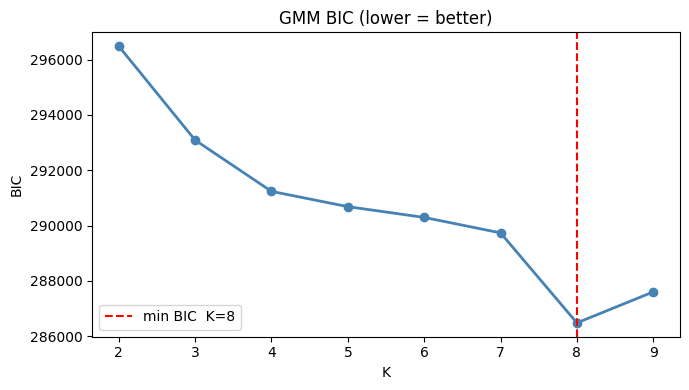


Selected K = 8 (BIC minimum)


In [45]:
K_RANGE = range(2, 10)
np.random.seed(42)

bic_scores = []

for k in K_RANGE:
    gmm = GaussianMixture(n_components=k, covariance_type='full',
                          random_state=42, n_init=5)
    gmm.fit(X_clust)
    bic_scores.append(gmm.bic(X_clust))
    print(f"  K={k}  BIC={bic_scores[-1]:,.0f}")

ks = list(K_RANGE)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, bic_scores, 'o-', color='steelblue', lw=2)
ax.axvline(ks[np.argmin(bic_scores)], color='red', ls='--',
           label=f'min BIC  K={ks[np.argmin(bic_scores)]}')
ax.set(xlabel='K', ylabel='BIC', title='GMM BIC (lower = better)')
ax.legend(); plt.tight_layout(); plt.show()

K_OPT = ks[np.argmin(bic_scores)]
print(f"\nSelected K = {K_OPT} (BIC minimum)")

## Fit final GMM

In [ ]:
# ── Override K here if you want a specific number 
K_OPT = 4

gmm_final = GaussianMixture(n_components=K_OPT, covariance_type='full',
                             random_state=42, n_init=20)
gmm_final.fit(X_clust)

labels   = gmm_final.predict(X_clust)
probs    = gmm_final.predict_proba(X_clust)   # soft assignment probabilities

result = meta.copy()
result[CLUST_FEATURES] = X_clust.values
result['cluster']      = labels
result['max_prob']     = probs.max(axis=1)    # confidence of assignment

print(f"Cluster sizes:")
print(result['cluster'].value_counts().sort_index().to_string())
print(f"\nMean assignment confidence: {result['max_prob'].mean():.3f}")

Cluster sizes:
cluster
0    12998
1     7201
2    16862
3     2934

Mean assignment confidence: 0.771


## Cluster profiling

In [ ]:
# ── Factor score means per cluster 
profile = result.groupby('cluster')[CLUST_FEATURES].mean().round(3)
profile['n'] = result['cluster'].value_counts().sort_index()
profile['pct'] = (profile['n'] / len(result) * 100).round(1)
print("=== Cluster factor-score profiles ===")
print(profile.to_string())

# ── Gender composition per cluster 
gender_comp = (
    result.groupby(['cluster','gender']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Gender composition (%) ===")
print(gender_comp.to_string())

# ── Tournament composition per cluster
tourn_comp = (
    result.groupby(['cluster','tournament']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Tournament composition (%) ===")
print(tourn_comp.to_string())

=== Cluster factor-score profiles ===
            F1     F2     F3      n   pct
cluster                                  
0        0.812 -0.296  0.064  12998  32.5
1       -1.511 -0.398 -0.043   7201  18.0
2        0.052  0.386 -0.402  16862  42.2
3       -0.186  0.067  2.129   2934   7.3

=== Gender composition (%) ===
gender    Men  Women
cluster             
0        50.8   49.2
1        42.8   57.2
2        61.3   38.7
3        60.1   39.9

=== Tournament composition (%) ===
tournament  EURO2020  EURO2024  WC2022  WEURO2022  WEURO2025  WWC2023
cluster                                                              
0               16.8      13.6    20.4       12.1       11.5     25.6
1               12.2      12.8    17.8       12.7       12.6     32.0
2               18.5      19.3    23.6        9.8       10.1     18.7
3               19.0      17.8    23.3        8.0       10.4     21.4


## Visualisation — scatter matrix & radar

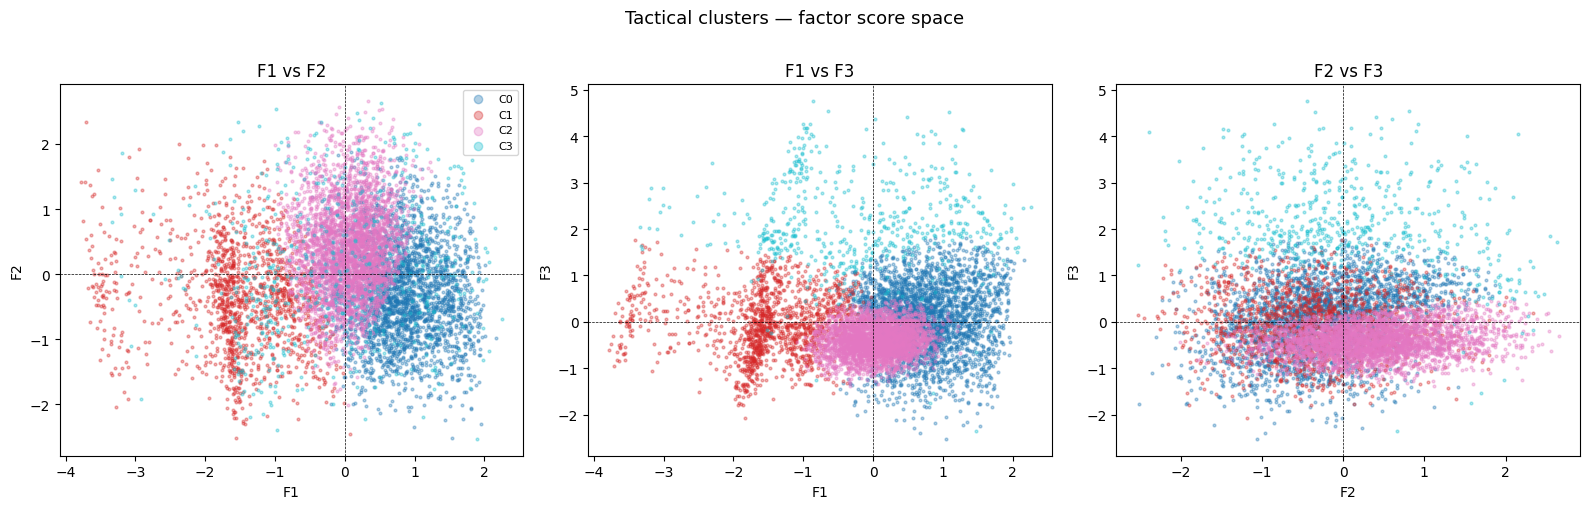

In [48]:
PALETTE = plt.cm.tab10(np.linspace(0, 0.9, K_OPT))
LABEL_MAP = {c: f"C{c}" for c in range(K_OPT)}  # replace with tactical names after profiling

# ── 2D scatter: F1 vs F2, F1 vs F3, F2 vs F3 ─────────────────────────────────
pairs = [(CLUST_FEATURES[0], CLUST_FEATURES[1]),
         (CLUST_FEATURES[0], CLUST_FEATURES[2]),
         (CLUST_FEATURES[1], CLUST_FEATURES[2])]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sample = result.sample(min(8000, len(result)), random_state=42)

for ax, (xf, yf) in zip(axes, pairs):
    for c in range(K_OPT):
        m = sample['cluster'] == c
        ax.scatter(sample.loc[m, xf], sample.loc[m, yf],
                   s=4, alpha=0.35, color=PALETTE[c], label=LABEL_MAP[c])
    ax.set(xlabel=xf, ylabel=yf, title=f"{xf} vs {yf}")
    ax.axhline(0, color='k', lw=0.5, ls='--')
    ax.axvline(0, color='k', lw=0.5, ls='--')

axes[0].legend(markerscale=3, fontsize=8)
plt.suptitle('Tactical clusters — factor score space', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()

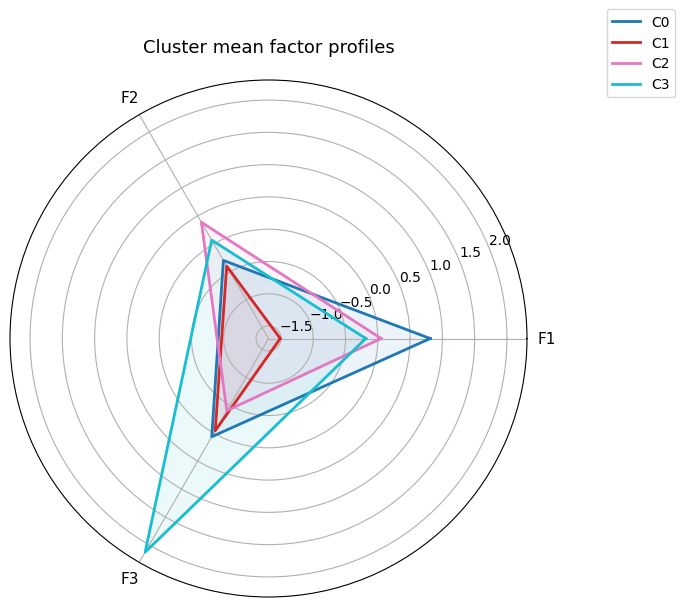

In [49]:
# ── Radar chart — cluster mean profiles ──────────────────────────────────────
angles = np.linspace(0, 2 * np.pi, len(CLUST_FEATURES), endpoint=False).tolist()
angles += angles[:1]  # close the loop

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

for c in range(K_OPT):
    vals = profile.loc[c, CLUST_FEATURES].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=PALETTE[c], lw=2, label=LABEL_MAP[c])
    ax.fill(angles, vals, color=PALETTE[c], alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(CLUST_FEATURES, size=11)
ax.set_title('Cluster mean factor profiles', size=13, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.15))
plt.tight_layout(); plt.show()

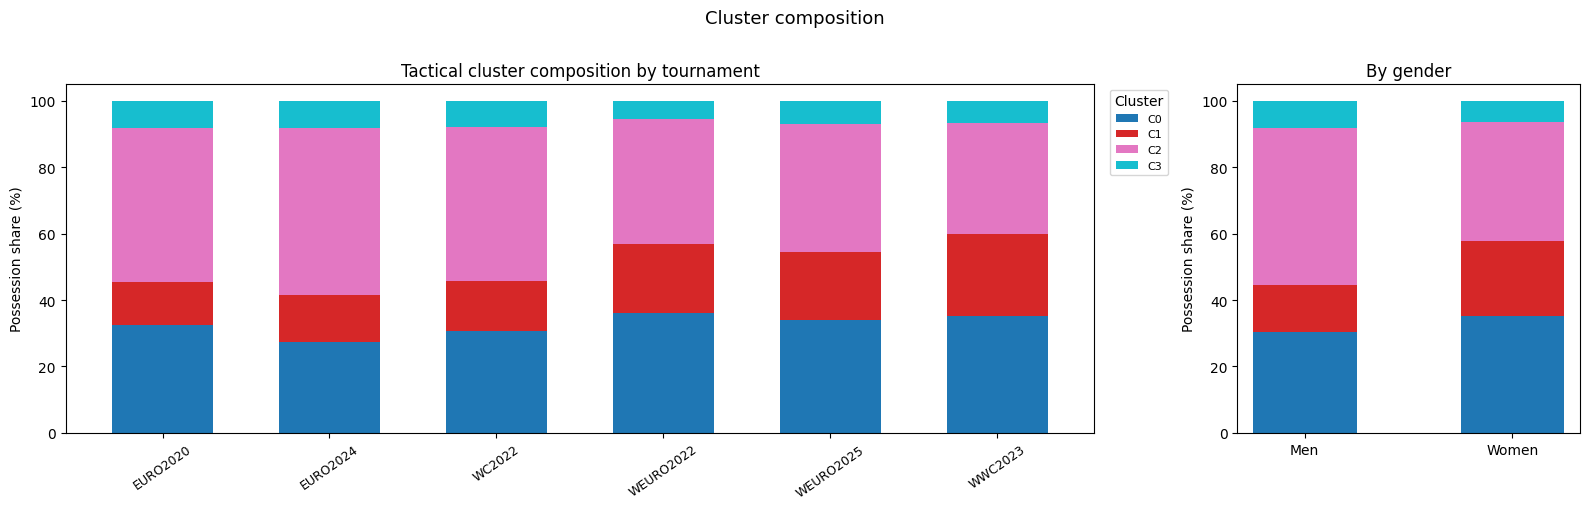

In [50]:
# ── Stacked bar: cluster share by tournament & by gender ─────────────────────
tourn_order = (
    result.groupby('tournament')['gender']
    .first().sort_values().index.tolist()
)

comp_tourn = (
    result.groupby(['tournament', 'cluster']).size()
    .unstack(fill_value=0).loc[tourn_order]
    .apply(lambda r: r / r.sum() * 100, axis=1)
)

comp_gender = (
    result.groupby(['gender', 'cluster']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5),
                          gridspec_kw={'width_ratios': [3, 1]})

# Left: by tournament
bottom = np.zeros(len(comp_tourn))
for c in range(K_OPT):
    vals = comp_tourn[c].values if c in comp_tourn.columns else np.zeros(len(comp_tourn))
    axes[0].bar(comp_tourn.index, vals, bottom=bottom,
                color=PALETTE[c], label=LABEL_MAP[c], width=0.6)
    bottom += vals
axes[0].set(ylabel='Possession share (%)',
            title='Tactical cluster composition by tournament')
axes[0].tick_params(axis='x', rotation=35, labelsize=9)
axes[0].legend(title='Cluster', bbox_to_anchor=(1.01, 1), loc='upper left',
               fontsize=8)

# Right: by gender
bottom = np.zeros(len(comp_gender))
for c in range(K_OPT):
    vals = comp_gender[c].values if c in comp_gender.columns else np.zeros(len(comp_gender))
    axes[1].bar(comp_gender.index, vals, bottom=bottom,
                color=PALETTE[c], width=0.5)
    bottom += vals
axes[1].set(ylabel='Possession share (%)',
            title='By gender')
axes[1].tick_params(axis='x', labelsize=10)

plt.suptitle('Cluster composition', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()


## Cluster Labels & Interpretation

```python
LABEL_MAP = {
    0: "Fast Open Play",        # F1↑  F2↓  F3~
    1: "Slow Open Possession",  # F1↓↓ F2↓  F3~
    2: "Compact Positional",    # F1~  F2↑  F3↓
    3: "Direct Long-Ball",      # F1~  F2~  F3↑↑
}
```

---

### Cluster 0 — Fast Open Play (32.5 %)

- **F1 = +0.81** (fast tempo), **F2 = −0.30** (open/dispersed), **F3 ≈ 0**
- High passing frequency with a spatially spread formation — rapid ball
  circulation but without compact positional organisation.
- Gender: balanced (51 % Men / 49 % Women). No strong gender signature;
  fast open play is a universal tactical style.
- Tournament: slightly over-represented in WWC2023 (25.6 %) and WC2022 (20.4 %).

### Cluster 1 — Slow Open Possession (18.0 %)

- **F1 = −1.51** (clearly slow), **F2 = −0.40** (open), **F3 ≈ 0**
- Low passing rate with a spread formation — deliberate, unhurried possession
  without spatial compactness. Consistent with time-holding or recovery phases.
- Gender: **Women-leaning (57.2 %)**, highest women's share of any cluster.
  WWC2023 alone accounts for 32.0 % of this cluster — slow open play is the
  dominant possession mode in women's World Cup football.

### Cluster 2 — Compact Positional (42.2 %)

- **F1 ≈ 0** (average tempo), **F2 = +0.39** (compact / spread), **F3 = −0.40** (low direct)
- Average passing rate, spatially tight formation, low long-ball tendency —
  controlled short-passing within a structured positional shape.
- Gender: **Men-dominant (61.3 %)**, the strongest gender imbalance. Concentrated
  in EURO2024 (19.3 %) and WC2022 (23.6 %). Compact positional play is the
  defining mode of modern men's international football.
- Largest cluster (42 %): the modal tactical style across the combined dataset.

### Cluster 3 — Direct Long-Ball (7.3 %)

- **F1 ≈ 0**, **F2 ≈ 0**, **F3 = +2.13** (extreme)
- Near-average tempo and spatial spread, but ball travels very far per touch
  at high speed with reduced accuracy — the hallmark of long / aerial distribution.
- Gender: Men-leaning (60.1 %). Concentrated in men's tournaments
  (WC2022 23.3 %, EURO2020 19.0 %); women's tournaments under-represented
  (WEURO2022 8.0 %).
- Smallest cluster (7.3 %): a specialised, situational style (clearances,
  goal-kicks played long, switches of play).


In [ ]:
# ── Save cluster labels back to h5 
save_df = result[["game_id","possession","possession_team_id",
                   "tournament","gender","cluster","max_prob"] + CLUST_FEATURES].copy()
save_df.to_hdf(spadl_h5, key="tactical_clusters", mode="a", complevel=5)
print(f"Saved tactical_clusters → {spadl_h5}  ({len(save_df):,} rows)")
save_df.head()

Saved tactical_clusters → ../data/women-statsbomb3.h5  (39,995 rows)


,game_id,possession,possession_team_id,tournament,gender,cluster,max_prob,F1,F2,F3
0,4020846,2,865,WEURO2025,Women,0,0.843907,0.540163,0.584086,0.599961
1,4020846,4,865,WEURO2025,Women,0,0.774364,0.725761,0.040628,0.212298
2,4020846,5,865,WEURO2025,Women,3,0.516955,-0.011667,0.177026,1.450351
3,4020846,6,863,WEURO2025,Women,2,0.827887,0.032411,0.282278,-0.760764
4,4020846,7,865,WEURO2025,Women,2,0.760673,-0.306674,-0.463080,-0.565041


## Fit final GMM for TI_horst
We follow the exact same logic here but only using `TI_horst` as the feature.

  K=2  BIC=113,081
  K=3  BIC=112,721
  K=4  BIC=112,816
  K=5  BIC=112,887
  K=6  BIC=112,862
  K=7  BIC=112,888
  K=8  BIC=112,851
  K=9  BIC=112,904


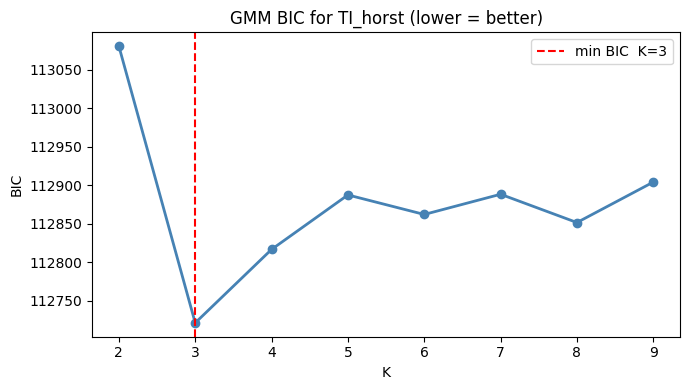


Selected K = 3 (BIC minimum)


In [4]:
# Prepare features for TI_horst
X_horst = efa_df[['TI_horst']].dropna()
meta_horst = efa_df.loc[X_horst.index, ["game_id","possession","possession_team_id", "tournament","gender"]]

# Model selection - BIC
K_RANGE = range(2, 10)
np.random.seed(42)

bic_scores_horst = []

for k in K_RANGE:
    gmm = GaussianMixture(n_components=k, covariance_type='full',
                          random_state=42, n_init=5)
    gmm.fit(X_horst)
    bic_scores_horst.append(gmm.bic(X_horst))
    print(f"  K={k}  BIC={bic_scores_horst[-1]:,.0f}")

ks = list(K_RANGE)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, bic_scores_horst, 'o-', color='steelblue', lw=2)
ax.axvline(ks[np.argmin(bic_scores_horst)], color='red', ls='--',
           label=f'min BIC  K={ks[np.argmin(bic_scores_horst)]}')
ax.set(xlabel='K', ylabel='BIC', title='GMM BIC for TI_horst (lower = better)')
ax.legend(); plt.tight_layout(); plt.show()

K_OPT_HORST = ks[np.argmin(bic_scores_horst)]
print(f"\nSelected K = {K_OPT_HORST} (BIC minimum)")

In [ ]:
# Override K here if you want a specific number 
# K_OPT_HORST = 4 

gmm_final_horst = GaussianMixture(n_components=K_OPT_HORST, covariance_type='full',
                             random_state=42, n_init=20)
gmm_final_horst.fit(X_horst)

labels_horst   = gmm_final_horst.predict(X_horst)
probs_horst    = gmm_final_horst.predict_proba(X_horst)   

result_horst = meta_horst.copy()
result_horst['TI_horst'] = X_horst.values
result_horst['cluster']      = labels_horst
result_horst['max_prob']     = probs_horst.max(axis=1)    

print(f"Cluster sizes:")
print(result_horst['cluster'].value_counts().sort_index().to_string())
print(f"\nMean assignment confidence: {result_horst['max_prob'].mean():.3f}")

Cluster sizes:
cluster
0    25502
1     8528
2     5965

Mean assignment confidence: 0.728


In [ ]:
# ── Cluster profiling for TI_horst
profile_horst = result_horst.groupby('cluster')[['TI_horst']].mean().round(3)
profile_horst['n'] = result_horst['cluster'].value_counts().sort_index()
profile_horst['pct'] = (profile_horst['n'] / len(result_horst) * 100).round(1)
print("=== Cluster TI_horst profiles ===")
print(profile_horst.to_string())

# ── Gender composition per cluster 
gender_comp_horst = (
    result_horst.groupby(['cluster','gender']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Gender composition (%) ===")
print(gender_comp_horst.to_string())

# ── Tournament composition per cluster
tourn_comp_horst = (
    result_horst.groupby(['cluster','tournament']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Tournament composition (%) ===")
print(tourn_comp_horst.to_string())

=== Cluster TI_horst profiles ===
         TI_horst      n   pct
cluster                       
0          -0.055  25502  63.8
1           1.304   8528  21.3
2          -1.630   5965  14.9

=== Gender composition (%) ===
gender    Men  Women
cluster             
0        53.5   46.5
1        71.2   28.8
2        34.7   65.3

=== Tournament composition (%) ===
tournament  EURO2020  EURO2024  WC2022  WEURO2022  WEURO2025  WWC2023
cluster                                                              
0               17.1      15.7    20.6       11.5       11.5     23.4
1               20.9      21.7    28.7        6.3        7.5     14.9
2                9.9       9.9    14.8       15.1       14.0     36.2
